# code_067 · Random grouped and nested validation

**Book:** section 14.1. A self-contained deployment-matched validation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_14_GUIDE.md), [run evidence](../CHAPTER_14_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_067).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1467;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1467


<a id="units"></a>
## Same rows, different generalization questions

Generate 60 buildings with 12 members measured twice: 1,440 rows. Each building has a two-coordinate fingerprint and a random unmeasured response offset. Each member has one feature repeated with slight measurement noise. Target = 1.2*member feature + .9*building offset + .1 observation noise. The fingerprint permits local recognition without identifying the offset for a new building. This is an intentionally hierarchical synthetic fixture, not field data. Development contains buildings 0–44; buildings 45–59 are locked final assessment. A fixed standardized five-neighbor regressor is compared under shuffled row KFold(5) and GroupKFold(5). Building and row weighting agree here because all buildings have 24 rows; neither is a confidence interval.


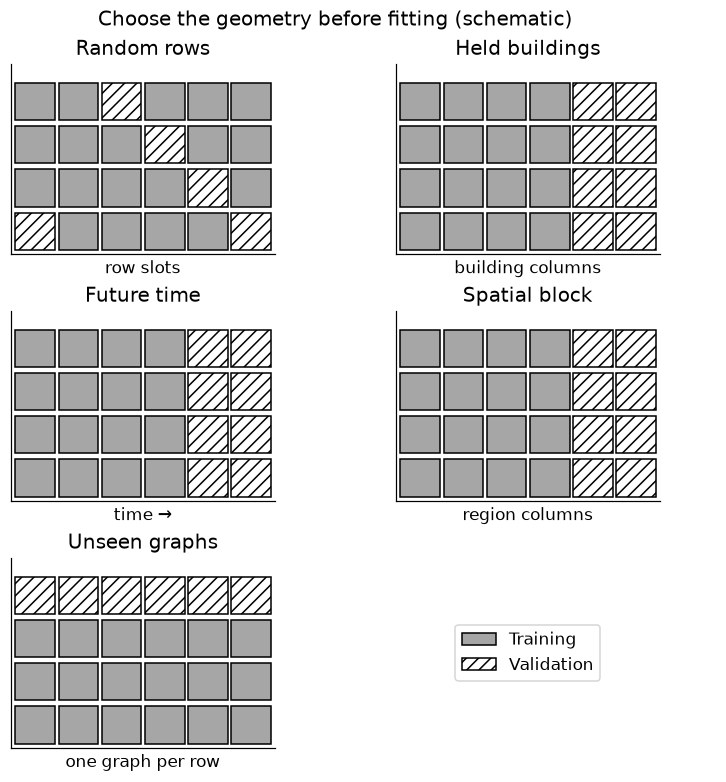

In [2]:
from sklearn.model_selection import KFold,GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from matplotlib.patches import Rectangle,Patch
group=np.repeat(np.arange(60),24);finger=rng.normal(size=(60,2));offset=rng.normal(size=60);member=np.repeat(rng.normal(size=(60,12)),2,axis=1).ravel()
X=np.column_stack([finger[group],member+rng.normal(0,.02,len(group))]);y=1.2*member+.9*offset[group]+rng.normal(0,.1,len(group));dev=np.flatnonzero(group<45);final=np.flatnonzero(group>=45)
assert len(dev)==1080 and len(final)==360 and not set(group[dev])&set(group[final])
def estimator(name):
 return make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=int(name[3:]))) if name.startswith('knn') else make_pipeline(StandardScaler(),Ridge(alpha=float(name[5:])))
def evaluate(ids,splits,name,require_groups=False):
 pred=np.full(len(ids),np.nan)
 for tr,va in splits:
  if require_groups:assert not set(group[ids[tr]])&set(group[ids[va]])
  pred[va]=estimator(name).fit(X[ids[tr]],y[ids[tr]]).predict(X[ids[va]])
 assert np.isfinite(pred).all()
 return float(mean_squared_error(y[ids],pred))
row=evaluate(dev,KFold(5,shuffle=True,random_state=SEED).split(dev),'knn5');grouped=evaluate(dev,GroupKFold(5).split(dev,groups=group[dev]),'knn5',True)
RESULTS['fixed_knn5']={'row_cv_mse':row,'building_cv_mse':grouped,'development_buildings':45,'rows_per_building':24,'final_buildings':15}
# Schematic geometries, not observations or empirical split scores.
fig,axes=plt.subplots(3,2,figsize=(7,7));names=['Random rows','Held buildings','Future time','Spatial block','Unseen graphs']
for k,ax in enumerate(axes.flat[:5]):
 for j in range(24):
  r,c=divmod(j,6);held=(j%5==0 if k==0 else c>=4 if k in [1,2,3] else r==3)
  ax.add_patch(Rectangle((c,r),.92,.86,facecolor='white' if held else '.65',edgecolor='black',hatch='///' if held else None))
 ax.set(xlim=(-.1,6),ylim=(-.1,4.3),title=names[k],xticks=[],yticks=[]);ax.set_aspect('equal')
 for j,label in enumerate(['row slots','building columns','time →','region columns','one graph per row']):
  if j==k:ax.set_xlabel(label)
axes.flat[5].axis('off');axes.flat[5].legend(handles=[Patch(facecolor='.65',edgecolor='black',label='Training'),Patch(facecolor='white',edgecolor='black',hatch='///',label='Validation')],loc='center');fig.suptitle('Choose the geometry before fitting (schematic)');plt.show()


<a id="nested"></a>
## Evaluate the selection procedure outside the search

Five predeclared candidates: standardized KNN k=1,5,15 and Ridge alpha=.1,10. Every outer training fold performs a three-fold grouped inner search. Inner scores choose a candidate; only its refitted outer-training pipeline predicts outer held buildings. A final three-fold grouped search on all development data chooses a procedure fitted to all 45 development buildings, followed by one locked 15-building score. No final labels enter search. Outer scores assess a procedure trained on 36 buildings, not exactly the all-45 fit. Repeated adaptive redesign after seeing outer scores would consume this boundary.


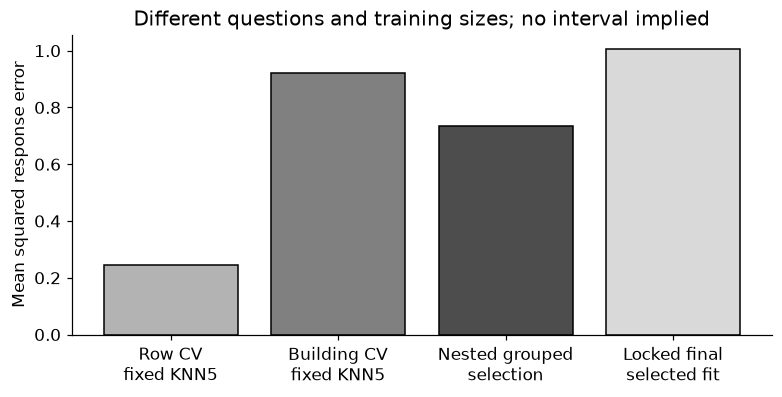

In [3]:
candidates=['knn1','knn5','knn15','ridge0.1','ridge10']
def choose(ids):
 scores={name:evaluate(ids,GroupKFold(3).split(ids,groups=group[ids]),name,True) for name in candidates}
 return min(scores,key=scores.get),scores
outer=[];oof=np.full(len(dev),np.nan)
for tr,va in GroupKFold(5).split(dev,groups=group[dev]):
 train_ids=dev[tr];valid_ids=dev[va];assert not set(group[train_ids])&set(group[valid_ids])
 name,inner=choose(train_ids);p=estimator(name).fit(X[train_ids],y[train_ids]).predict(X[valid_ids]);oof[va]=p;outer.append({'choice':name,'mse':float(mean_squared_error(y[valid_ids],p)),'inner_scores':inner})
name,inner=choose(dev);fitted=estimator(name).fit(X[dev],y[dev]);p=fitted.predict(X[final]);assert np.isfinite(oof).all()
RESULTS['nested']={'outer_folds':outer,'outer_pooled_mse':float(mean_squared_error(y[dev],oof)),'final_choice':name,'all_development_inner_scores':inner,'locked_final_mse':float(mean_squared_error(y[final],p)),'weighting':'equal rows = equal buildings (24 rows each)'}
fig,ax=plt.subplots(figsize=(7,3.5));values=[row,grouped,RESULTS['nested']['outer_pooled_mse'],RESULTS['nested']['locked_final_mse']];ax.bar(range(4),values,color=['.7','.5','.3','.85'],edgecolor='black');ax.set(xticks=range(4),xticklabels=['Row CV\nfixed KNN5','Building CV\nfixed KNN5','Nested grouped\nselection','Locked final\nselected fit'],ylabel='Mean squared response error',title='Different questions and training sizes; no interval implied');plt.show()


In [4]:
summary={'example_id':'code_067','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['exchangeability and repeated member measurements', 'row versus building split', 'nested grouped model selection', 'locked new-building assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["exchangeability and repeated member measurements", "row versus building split", "nested grouped model selection", "locked new-building assessment"], "elapsed_seconds": 0.386, "example_id": "code_067", "hardware": "Darwin arm64 CPU", "results": {"fixed_knn5": {"building_cv_mse": 0.9214659070082938, "development_buildings": 45, "final_buildings": 15, "row_cv_mse": 0.24418472612170622, "rows_per_building": 24}, "nested": {"all_development_inner_scores": {"knn1": 1.0802666973565656, "knn15": 0.8527872983339524, "knn5": 1.0229249332124428, "ridge0.1": 0.7723972676113366, "ridge10": 0.7697412163392566}, "final_choice": "ridge10", "locked_final_mse": 1.006046019645541, "outer_folds": [{"choice": "ridge10", "inner_scores": {"knn1": 1.1582752342001816, "knn15": 1.034578317360231, "knn5": 1.1143420891555198, "ridge0.1": 0.7185706853824056, "ridge10": 0.7141638144563024}, "mse": 0.8721649165926745}, {"choice": "ridge10", "inner_scores": {"knn1": 